In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path().resolve().parent / "src"))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from constraints import (
    ConstraintLibrary, ConstraintEvaluator,
    FractionationType, GDPHMM_TO_CONSTRAINT_ORGAN
)
from data import GDPHMM_OAR_V3, GDPHMM_DATA_BASE_PATH, GDPHMM_DOSE_MAX
from evaluator import GDPHMM_UNIQUE_OAR
from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED, get_metric_label, is_higher_better, get_metric_abbr, get_metric_unit, setup_fig_axes, draw_ptv_overlay, draw_ptv_contours, draw_oar_contours, draw_beam_overlay

In [3]:
dataset = build_dataset('test')
# beamdiff_best_pred = ModelResults('165-ws-rfm-combi-fp32', 'flow-cache-beamdiff-enc2-interval5-20-200-inf-2-bf16-amp', 199, 'test', dataset)
beamdiff_best_pred = ModelResults('101-beamdiff', 'ddpm-1000', 199, 'test', dataset)

In [ ]:
library = ConstraintLibrary()
evaluator = ConstraintEvaluator(library.constraints)
fractionation = FractionationType.CONVENTIONAL
voxel_volume_cc = 2.5 * 2.5 * 2.0 / 1000.0  # mm³ to cm³

file_names = beamdiff_best_pred.volume_metrics['file_name'].unique()
all_violations = []

for file_name in file_names:
    sample_name = file_name.replace('.npz', '')
    sample = beamdiff_best_pred.for_sample(sample_name)
    structure, target_dose = sample.load_orig_volume()
    pred_dose = sample.load_pred_volume()

    # Build organ masks dict mapping constraint organ names to masks
    organ_masks = {}
    for oar_name in GDPHMM_UNIQUE_OAR:
        oar_index = dataset.selector.get_oar_index(oar_name)
        mask = structure[oar_index] > 0
        if mask.sum() == 0:
            continue
        constraint_organ = GDPHMM_TO_CONSTRAINT_ORGAN.get(oar_name)
        if constraint_organ:
            organ_masks[constraint_organ] = mask

    # Evaluate constraints for pred and target
    pred_results = evaluator.evaluate_all_constraints(pred_dose, organ_masks, voxel_volume_cc, fractionation)
    target_results = evaluator.evaluate_all_constraints(target_dose, organ_masks, voxel_volume_cc, fractionation)

    for organ, results in pred_results.items():
        target_organ_results = {r['description']: r for r in target_results.get(organ, [])}
        for r in results:
            target_r = target_organ_results.get(r['description'], {})
            all_violations.append({
                'sample': sample_name,
                'organ': organ,
                'dataset_organ': [k for k, v in GDPHMM_TO_CONSTRAINT_ORGAN.items() if v == organ and k in GDPHMM_UNIQUE_OAR][0],
                'constraint': r['description'],
                'grade': str(r['constraint'].grade.value) if r['constraint'].grade else None,
                'pred_value': r['value'],
                'limit': r['limit'],
                'pred_satisfied': r['satisfied'],
                'pred_margin': r['margin'],
                'target_value': target_r.get('value'),
                'target_satisfied': target_r.get('satisfied'),
            })

violations_df = pd.DataFrame(all_violations)
print(f"Total constraint evaluations: {len(violations_df)}")
print(f"Pred violated: {(~violations_df['pred_satisfied']).sum()}")
print(f"Target violated: {(~violations_df['target_satisfied']).sum()}")

In [ ]:
violations_df.to_csv('../samples/101-beamdiff/ddpm-1000/test_199/_constraint_violations.csv', index=False)

In [5]:
violations_df = pd.read_csv('../samples/165-ws-rfm-combi-fp32/flow-cache-beamdiff-enc2-interval5-20-200-inf-2-bf16-amp/test_199/_constraint_violations.csv')

In [6]:
# Summary: violation rate per organ and constraint
pred_violated = violations_df[~violations_df['pred_satisfied']].copy()

# Count how often each organ+constraint is violated across samples
violation_counts = (
    violations_df
    .groupby(['organ', 'constraint', 'grade'])
    .agg(
        n_samples=('sample', 'count'),
        pred_violation_count=('pred_satisfied', lambda x: (~x).sum()),
        target_violation_count=('target_satisfied', lambda x: (~x).sum()),
        pred_mean_margin=('pred_margin', 'mean'),
    )
    .assign(
        pred_violation_rate=lambda df: df['pred_violation_count'] / df['n_samples'] * 100,
        target_violation_rate=lambda df: df['target_violation_count'] / df['n_samples'] * 100,
    )
    .sort_values('pred_violation_rate', ascending=False)
)

# Show only violated constraints
violated_constraints = violation_counts[violation_counts['pred_violation_count'] > 0]
violated_constraints[['n_samples', 'pred_violation_count', 'pred_violation_rate', 'target_violation_count', 'target_violation_rate', 'pred_mean_margin']]

n_samples  \
organ        constraint                  grade                  
BoneMandible BoneMandible: D_MAX < 70 Gy mandatory         48   
             BoneMandible: V_55Gy < 20%  optimal           48   
Lips         Lips: D_MEAN < 30 Gy        optimal           48   

                                                    pred_violation_count  \
organ        constraint                  grade                             
BoneMandible BoneMandible: D_MAX < 70 Gy mandatory                     5   
             BoneMandible: V_55Gy < 20%  optimal                       3   
Lips         Lips: D_MEAN < 30 Gy        optimal                       2   

                                                    pred_violation_rate  \
organ        constraint                  grade                            
BoneMandible BoneMandible: D_MAX < 70 Gy mandatory            10.416667   
             BoneMandible: V_55Gy < 20%  optimal               6.250000   
Lips         Lips: D_MEAN < 30 Gy        optimal               4.166667   

                                                    target_violation_count  \
organ        constraint                  grade                               
BoneMandible BoneMandible: D_MAX < 70 Gy mandatory                       6   
             BoneMandible: V_55Gy < 20%  optimal                         2   
Lips         Lips: D_MEAN < 30 Gy        optimal                         0   

                                                    target_violation_rate  \
organ        constraint                  grade                              
BoneMandible BoneMandible: D_MAX < 70 Gy mandatory              12.500000   
             BoneMandible: V_55Gy < 20%  optimal                 4.166667   
Lips         Lips: D_MEAN < 30 Gy        optimal                 0.000000   

                                                    pred_mean_margin  
organ        constraint                  grade                        
BoneMandible BoneMandible: D_MAX < 70 Gy mandatory          6.950717  
             BoneMandible: V_55Gy < 20%  optimal           14.027852  
Lips         Lips: D_MEAN < 30 Gy        optimal           14.582061

In [7]:
# Violations unique to pred (target satisfies but pred doesn't)
violations_df['pred_only_violation'] = (~violations_df['pred_satisfied']) & (violations_df['target_satisfied'] == True)
pred_only = violations_df[violations_df['pred_only_violation']]

pred_only_counts = (
    pred_only
    .groupby(['organ', 'constraint', 'grade'])
    .agg(count=('sample', 'count'))
    .sort_values('count', ascending=False)
)
print(f"Constraints violated by pred but NOT by target: {len(pred_only)} instances")
pred_only_counts

Constraints violated by pred but NOT by target: 35 instances


count
organ        constraint                  grade           
Lips         Lips: D_MEAN < 30 Gy        optimal        2
BoneMandible BoneMandible: D_MAX < 70 Gy mandatory      1
             BoneMandible: V_55Gy < 20%  optimal        1

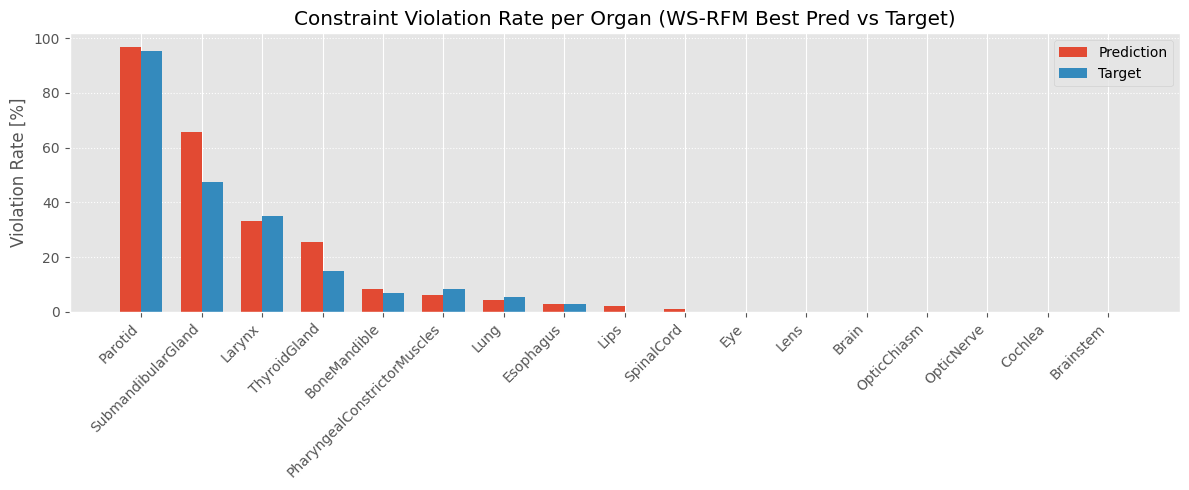

In [8]:
# Violation rate per organ (aggregated across all constraints)
organ_summary = (
    violations_df
    .groupby('organ')
    .agg(
        total_constraints=('pred_satisfied', 'count'),
        pred_violations=('pred_satisfied', lambda x: (~x).sum()),
        target_violations=('target_satisfied', lambda x: (~x).sum()),
        pred_only_violations=('pred_only_violation', 'sum'),
    )
    .assign(
        pred_violation_rate=lambda df: df['pred_violations'] / df['total_constraints'] * 100,
        target_violation_rate=lambda df: df['target_violations'] / df['total_constraints'] * 100,
    )
    .sort_values('pred_violation_rate', ascending=False)
)

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(organ_summary))
width = 0.35
ax.bar(x - width/2, organ_summary['pred_violation_rate'], width, label='Prediction', color='#E24A33')
ax.bar(x + width/2, organ_summary['target_violation_rate'], width, label='Target', color='#348ABD')
ax.set_xticks(x)
ax.set_xticklabels(organ_summary.index, rotation=45, ha='right')
ax.set_ylabel('Violation Rate [%]')
ax.set_title('Constraint Violation Rate per Organ (WS-RFM Best Pred vs Target)')
ax.legend()
ax.grid(True, axis='y', linestyle=':')
fig.tight_layout()
plt.show()

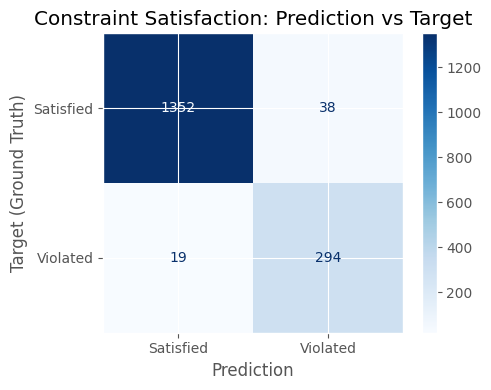

Both satisfied:              1352  (79.4%)
Both violated:                294  (17.3%)
Target satisfied, pred violated:   38  (2.2%)
Target violated, pred satisfied:   19  (1.1%)


In [28]:
# Confusion matrix: pred vs target constraint satisfaction
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    violations_df['target_satisfied'],
    violations_df['pred_satisfied'],
    labels=[True, False],
)

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Satisfied', 'Violated'],
)
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_xlabel('Prediction')
ax.set_ylabel('Target (Ground Truth)')
ax.set_title('Constraint Satisfaction: Prediction vs Target')
fig.tight_layout()
plt.show()

# Print rates
tn, fp, fn, tp = cm.ravel()
print(f"Both satisfied:              {cm[0,0]:4d}  ({cm[0,0]/cm.sum()*100:.1f}%)")
print(f"Both violated:               {cm[1,1]:4d}  ({cm[1,1]/cm.sum()*100:.1f}%)")
print(f"Target satisfied, pred violated: {cm[0,1]:4d}  ({cm[0,1]/cm.sum()*100:.1f}%)")
print(f"Target violated, pred satisfied: {cm[1,0]:4d}  ({cm[1,0]/cm.sum()*100:.1f}%)")

In [6]:
dangerous_violations_df = violations_df[violations_df['pred_satisfied'] & (~violations_df['target_satisfied'])]
dangerous_violations_df

,sample,organ,dataset_organ,constraint,grade,pred_value,limit,pred_satisfied,pred_margin,target_value,target_satisfied
192,HNSCC-01-0078+A4Ac+MOS_12319,BoneMandible,Mandible-PTV,BoneMandible: D_MAX < 70 Gy,mandatory,67.638466,70,True,2.361534,70.822708,False
391,HNSCC-01-0084+A4Ac+MOS_44704,Larynx,Larynx-PTV,Larynx: D_MAX < 66 Gy,NaN,62.257198,66,True,3.742802,67.458862,False
429,0522c0444+A4Ac+MOS_24107,Larynx,Larynx-PTV,Larynx: D_MAX < 66 Gy,NaN,62.841976,66,True,3.158024,69.671494,False
501,HNC_030+A4Ac+MOS_3259,Larynx,Larynx-PTV,Larynx: D_MAX < 66 Gy,NaN,63.493820,66,True,2.506180,66.113670,False
556,HNC_140+A4Ac+MOS_9927,BoneMandible,Mandible-PTV,BoneMandible: D_MAX < 70 Gy,mandatory,69.072693,70,True,0.927307,70.945702,False
562,HNC_140+A4Ac+MOS_9927,Lung,Lungs,Lung: V_20Gy <= 20%,NaN,19.160450,20,True,0.839550,21.300765,False
563,HNC_140+A4Ac+MOS_9927,Lung,Lungs,Lung: V_10Gy <= 40%,NaN,39.725026,40,True,0.274974,41.265662,False
716,HNC_031+A4Ac+MOS_58298,PharyngealConstrictorMuscles,PharConst-PTV,PharyngealConstrictorMuscles: D_MEAN < 50 Gy,NaN,46.776081,50,True,3.223919,52.945450,False
834,HNSCC-01-0155+A4Ac+MOS_17295,Parotid,ParotidCon-PTV,Parotid: V_30Gy < 50%,NaN,45.341228,50,True,4.658772,56.995949,False
1022,HNSCC-01-0026+A4Ac+MOS_5856,Lung,Lungs,Lung: V_40Gy <= 10%,NaN,7.223371,10,True,2.776629,12.274328,False


In [7]:
ok_violations_df = violations_df[violations_df['target_satisfied'] & (~violations_df['pred_satisfied'])]
ok_violations_df

,sample,organ,dataset_organ,constraint,grade,pred_value,limit,pred_satisfied,pred_margin,target_value,target_satisfied
66,HN-CHUM-011+S2A4Ac+MOS_13191,SubmandibularGland,SubmandL-PTV,SubmandibularGland: D_MEAN < 35 Gy,NaN,36.055660,35,False,-1.055660,30.620604,True
85,HN-HGJ-080+S2A4Ac+MOS_55964,ThyroidGland,Thyroid-PTV,ThyroidGland: V_45Gy < 50%,NaN,50.261780,50,False,-0.261780,43.455497,True
86,HN-HGJ-080+S2A4Ac+MOS_55964,ThyroidGland,Thyroid-PTV,ThyroidGland: D_MEAN < 45 Gy,NaN,45.180740,45,False,-0.180740,41.402782,True
125,HNC_119+A4Ac+MOS_5136,BoneMandible,Mandible-PTV,BoneMandible: D_MAX < 70 Gy,mandatory,70.011002,70,False,-0.011002,69.835709,True
169,HNC_199+A4Ac+MOS_357,Lips,Lips,Lips: D_MEAN < 30 Gy,optimal,32.294468,30,False,-2.294468,28.029045,True
176,HNSCC-01-0078+A4Ac+MOS_12319,Larynx,Larynx-PTV,Larynx: D_MAX < 50 Gy,NaN,51.084137,50,False,-1.084137,49.557274,True
278,HN-CHUM-051+A4Ac+MOS_4095,SubmandibularGland,SubmandL-PTV,SubmandibularGland: D_MEAN < 35 Gy,NaN,46.708061,35,False,-11.708061,32.947731,True
370,HNC_211+A4Ac+MOS_2926,ThyroidGland,Thyroid-PTV,ThyroidGland: V_45Gy < 50%,NaN,80.180180,50,False,-30.180180,40.540541,True
371,HNC_211+A4Ac+MOS_2926,ThyroidGland,Thyroid-PTV,ThyroidGland: D_MEAN < 45 Gy,NaN,49.188801,45,False,-4.188801,41.135128,True
454,0522c0444+A4Ac+MOS_24107,Lung,Lungs,Lung: V_5Gy <= 50%,NaN,52.146685,50,False,-2.146685,42.417950,True


In [8]:
dangerous_violations_df['dataset_organ'].value_counts()

dataset_organ
Larynx-PTV        7
Lungs             5
Mandible-PTV      2
PharConst-PTV     2
Thyroid-PTV       2
ParotidCon-PTV    1
Name: count, dtype: int64

In [9]:
ok_violations_df['dataset_organ'].value_counts()

dataset_organ
Thyroid-PTV       12
SubmandL-PTV       9
Mandible-PTV       4
Larynx-PTV         4
ParotidCon-PTV     4
Lips               2
Lungs              1
PharConst-PTV      1
SpinalCord_05      1
Name: count, dtype: int64

In [10]:
dangerous_violations_df['sample'].value_counts()

sample
HNC_140+A4Ac+MOS_9927           3
HNC_107+A4Ac+MOS_49283          3
HN-HGJ-009+S2A4Ac+MOS_16685     2
HN-HGJ-064+S2A4Ac+MOS_40817     2
HNSCC-01-0078+A4Ac+MOS_12319    1
HNSCC-01-0084+A4Ac+MOS_44704    1
0522c0444+A4Ac+MOS_24107        1
HNC_030+A4Ac+MOS_3259           1
HNC_031+A4Ac+MOS_58298          1
HNSCC-01-0155+A4Ac+MOS_17295    1
HNSCC-01-0026+A4Ac+MOS_5856     1
HNSCC-01-0164+A4Ac+MOS_52248    1
0522c0723+A4Ac+MOS_2890         1
Name: count, dtype: int64

In [11]:
pd.concat((ok_violations_df['sample'], dangerous_violations_df['sample'])).value_counts()

sample
HNC_107+A4Ac+MOS_49283          4
HNC_140+A4Ac+MOS_9927           4
HNSCC-01-0026+A4Ac+MOS_5856     3
HNC_031+A4Ac+MOS_58298          3
HN-HGJ-064+S2A4Ac+MOS_40817     3
HNC_168+A4Ac+MOS_31266          3
HNSCC-01-0006+A4Ac+MOS_15521    3
HN-CHUS-102+S2A4Ac+MOS_51735    3
HNC_176+A4Ac+MOS_5603           2
HN-CHUM-007+S2A4Ac+MOS_28117    2
HNSCC-01-0035+A4Ac+MOS_49150    2
HN-HGJ-080+S2A4Ac+MOS_55964     2
HN-HGJ-009+S2A4Ac+MOS_16685     2
0522c0444+A4Ac+MOS_24107        2
HNC_211+A4Ac+MOS_2926           2
HNSCC-01-0078+A4Ac+MOS_12319    2
0522c0629+A4Ac+MOS_1367         1
HNC_119+A4Ac+MOS_5136           1
0522c0723+A4Ac+MOS_2890         1
HNSCC-01-0164+A4Ac+MOS_52248    1
HNSCC-01-0155+A4Ac+MOS_17295    1
HNC_030+A4Ac+MOS_3259           1
HNSCC-01-0084+A4Ac+MOS_44704    1
HN-HGJ-074+S2A4Ac+MOS_10993     1
HNC_199+A4Ac+MOS_357            1
HNSCC-01-0090+A4Ac+MOS_36890    1
HNSCC-01-0195+A4Ac+MOS_58481    1
HNC_169+A4Ac+MOS_33719          1
HN-CHUM-051+A4Ac+MOS_4095       1
HN-CHUM

In [13]:
# Count voxels in the organ mask for each violation — one structure load per sample
all_organs_per_sample = (
    pd.concat([
        ok_violations_df[['sample', 'dataset_organ']],
        dangerous_violations_df[['sample', 'dataset_organ']],
    ])
    .drop_duplicates()
    .groupby('sample')['dataset_organ']
    .apply(list)
)

voxel_counts = {}
for sample_name, oar_names in all_organs_per_sample.items():
    s = beamdiff_best_pred.for_sample(sample_name)
    structure, _ = s.load_orig_volume()
    for oar_name in oar_names:
        oar_index = dataset.selector.get_oar_index(oar_name)
        voxel_counts[(sample_name, oar_name)] = int((structure[oar_index] > 0).sum())

def add_voxel_count(df):
    return df.assign(voxel_count=df.apply(
        lambda r: voxel_counts.get((r['sample'], r['dataset_organ'])), axis=1
    ))

ok_violations_df = add_voxel_count(ok_violations_df)
dangerous_violations_df = add_voxel_count(dangerous_violations_df)

print('ok_violations_df voxel counts:')
display(ok_violations_df[['sample', 'dataset_organ', 'constraint', 'voxel_count']])

print('\ndangerous_violations_df voxel counts:')
display(dangerous_violations_df[['sample', 'dataset_organ', 'constraint', 'voxel_count']])


ok_violations_df voxel counts:


,sample,dataset_organ,constraint,voxel_count
66,HN-CHUM-011+S2A4Ac+MOS_13191,SubmandL-PTV,SubmandibularGland: D_MEAN < 35 Gy,271
85,HN-HGJ-080+S2A4Ac+MOS_55964,Thyroid-PTV,ThyroidGland: V_45Gy < 50%,191
86,HN-HGJ-080+S2A4Ac+MOS_55964,Thyroid-PTV,ThyroidGland: D_MEAN < 45 Gy,191
125,HNC_119+A4Ac+MOS_5136,Mandible-PTV,BoneMandible: D_MAX < 70 Gy,4487
169,HNC_199+A4Ac+MOS_357,Lips,Lips: D_MEAN < 30 Gy,2029
176,HNSCC-01-0078+A4Ac+MOS_12319,Larynx-PTV,Larynx: D_MAX < 50 Gy,324
278,HN-CHUM-051+A4Ac+MOS_4095,SubmandL-PTV,SubmandibularGland: D_MEAN < 35 Gy,446
370,HNC_211+A4Ac+MOS_2926,Thyroid-PTV,ThyroidGland: V_45Gy < 50%,111
371,HNC_211+A4Ac+MOS_2926,Thyroid-PTV,ThyroidGland: D_MEAN < 45 Gy,111
454,0522c0444+A4Ac+MOS_24107,Lungs,Lung: V_5Gy <= 50%,29860



dangerous_violations_df voxel counts:


,sample,dataset_organ,constraint,voxel_count
192,HNSCC-01-0078+A4Ac+MOS_12319,Mandible-PTV,BoneMandible: D_MAX < 70 Gy,2736
391,HNSCC-01-0084+A4Ac+MOS_44704,Larynx-PTV,Larynx: D_MAX < 66 Gy,377
429,0522c0444+A4Ac+MOS_24107,Larynx-PTV,Larynx: D_MAX < 66 Gy,1032
501,HNC_030+A4Ac+MOS_3259,Larynx-PTV,Larynx: D_MAX < 66 Gy,325
556,HNC_140+A4Ac+MOS_9927,Mandible-PTV,BoneMandible: D_MAX < 70 Gy,3193
562,HNC_140+A4Ac+MOS_9927,Lungs,Lung: V_20Gy <= 20%,20511
563,HNC_140+A4Ac+MOS_9927,Lungs,Lung: V_10Gy <= 40%,20511
716,HNC_031+A4Ac+MOS_58298,PharConst-PTV,PharyngealConstrictorMuscles: D_MEAN < 50 Gy,37
834,HNSCC-01-0155+A4Ac+MOS_17295,ParotidCon-PTV,Parotid: V_30Gy < 50%,2794
1022,HNSCC-01-0026+A4Ac+MOS_5856,Lungs,Lung: V_40Gy <= 10%,53673


In [48]:
violations_df[violations_df['sample'] == 'HNC_140+A4Ac+MOS_9927']

,sample,organ,dataset_organ,constraint,grade,pred_value,limit,pred_satisfied,pred_margin,target_value,target_satisfied
535,HNC_140+A4Ac+MOS_9927,PharyngealConstrictorMuscles,PharConst-PTV,PharyngealConstrictorMuscles: D_MEAN < 50 Gy,NaN,19.336229,50,True,30.663771,18.670414,True
536,HNC_140+A4Ac+MOS_9927,Brain,Brain,Brain: V_60cm3 <= 3%,NaN,0.000000,3,True,3.000000,0.000000,True
537,HNC_140+A4Ac+MOS_9927,Brain,Brain,Brain: D_MAX < 72 Gy,NaN,39.395226,72,True,32.604774,34.158321,True
538,HNC_140+A4Ac+MOS_9927,Larynx,Larynx-PTV,Larynx: D_MAX < 50 Gy,NaN,54.627579,50,False,-4.627579,49.235134,True
539,HNC_140+A4Ac+MOS_9927,Larynx,Larynx-PTV,Larynx: D_MAX < 66 Gy,NaN,54.627579,66,True,11.372421,49.235134,True
540,HNC_140+A4Ac+MOS_9927,Larynx,Larynx-PTV,Larynx: D_MEAN < 50 Gy,NaN,15.171235,50,True,34.828765,15.328186,True
541,HNC_140+A4Ac+MOS_9927,Larynx,Larynx-PTV,Larynx: V_50Gy < 27%,NaN,0.827586,27,True,26.172414,0.000000,True
542,HNC_140+A4Ac+MOS_9927,Cochlea,Cochlea_L,Cochlea: D_MEAN < 45 Gy,NaN,4.443141,45,True,40.556859,3.196223,True
543,HNC_140+A4Ac+MOS_9927,Esophagus,Esophagus,Esophagus: D_MEAN < 34 Gy,NaN,18.847946,34,True,15.152054,19.304537,True
544,HNC_140+A4Ac+MOS_9927,Esophagus,Esophagus,Esophagus: V_35Gy < 50%,NaN,16.600000,50,True,33.400000,21.800000,True


In [52]:
violations_df[(~violations_df['sample'].isin(ok_violations_df['sample'])) & (~violations_df['sample'].isin(dangerous_violations_df['sample']))]['sample'].unique()

array(['0522c0027+A4Ac+MOS_30413', '0522c0142+A4Ac+MOS_43691',
       'HNC_004+A4Ac+MOS_11506', 'HNC_135+A4Ac+MOS_2696',
       '0522c0555+A4Ac+MOS_22329', 'HN-CHUS-089+S2A4Ac+MOS_9626',
       'HNC_152+A4Ac+MOS_25955', 'HNSCC-01-0008+A4Ac+MOS_30671',
       'HNC_034+A4Ac+MOS_55214', 'HNC_159+A4Ac+MOS_19380',
       'HNC_053+A4Ac+MOS_6535', 'HNSCC-01-0187+A4Ac+MOS_3237',
       'HN-CHUM-003+S2A4Ac+MOS_20285', 'HNC_095+A4Ac+MOS_22308',
       'HNSCC-01-0057+A4Ac+MOS_50995', 'HNSCC-01-0060+A4Ac+MOS_19273',
       'HNSCC-01-0209+A4Ac+MOS_25555'], dtype=object)